In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

veri_yolu = '/content/drive/MyDrive/Deri_Lezyonu_Projesi/veri_seti'

siniflar = sorted(os.listdir(veri_yolu))
print("Bulunan sınıflar:", siniflar)

for sinif in siniflar:
    sinif_yolu = os.path.join(veri_yolu, sinif)
    if os.path.isdir(sinif_yolu):
        dosya_sayisi = len(os.listdir(sinif_yolu))
        print(f"{sinif}: {dosya_sayisi} görsel")

Bulunan sınıflar: ['atopic_dermatitis', 'chickenpox', 'herpes', 'impetigo', 'kizamik_measles', 'lyme', 'maymun_cicegi', 'scabies']
atopic_dermatitis: 612 görsel
chickenpox: 513 görsel
herpes: 559 görsel
impetigo: 153 görsel
kizamik_measles: 948 görsel
lyme: 953 görsel
maymun_cicegi: 670 görsel
scabies: 358 görsel


In [ ]:
from collections import Counter

for sinif in siniflar:
    sinif_yolu = os.path.join(veri_yolu, sinif)
    if os.path.isdir(sinif_yolu):
        uzantilar = [os.path.splitext(f)[1].lower() for f in os.listdir(sinif_yolu)]
        print(f"{sinif}: {Counter(uzantilar)}")

atopic_dermatitis: Counter({'.jpg': 612})
chickenpox: Counter({'.jpg': 411, '.png': 65, '.jpeg': 37})
herpes: Counter({'.jpg': 516, '.jpeg': 31, '.png': 12})
impetigo: Counter({'.jpg': 141, '.jpeg': 7, '.png': 5})
kizamik_measles: Counter({'.jpg': 815, '.png': 101, '.jpeg': 32})
lyme: Counter({'.jpg': 953})
maymun_cicegi: Counter({'.jpg': 474, '.png': 180, '.jpeg': 16})
scabies: Counter({'.jpg': 327, '.jpeg': 27, '.png': 4})


In [ ]:
from PIL import Image

bozuk_dosyalar = []

for sinif in siniflar:
    sinif_yolu = os.path.join(veri_yolu, sinif)
    if os.path.isdir(sinif_yolu):
        for dosya in os.listdir(sinif_yolu):
            dosya_yolu = os.path.join(sinif_yolu, dosya)
            try:
                img = Image.open(dosya_yolu)
                img.verify()  # dosyanın bozuk olup olmadığını kontrol eder
            except Exception as e:
                bozuk_dosyalar.append(dosya_yolu)

print(f"Toplam bozuk dosya sayısı: {len(bozuk_dosyalar)}")
for b in bozuk_dosyalar:
    print(b)

Toplam bozuk dosya sayısı: 0


In [ ]:
import random

for sinif in siniflar:
    sinif_yolu = os.path.join(veri_yolu, sinif)
    if os.path.isdir(sinif_yolu):
        dosyalar = os.listdir(sinif_yolu)
        ornek = random.sample(dosyalar, min(5, len(dosyalar)))
        print(f"\n{sinif} sınıfından örnek boyutlar:")
        for d in ornek:
            try:
                img = Image.open(os.path.join(sinif_yolu, d))
                print(f"  {d}: {img.size}, mod: {img.mode}")
            except:
                pass


atopic_dermatitis sınıfından örnek boyutlar:
  5T-0019.jpg: (646, 720), mod: RGB
  10IMG005.jpg: (720, 464), mod: RGB
  16IMG005.jpg: (473, 720), mod: RGB
  05atopic041105.jpg: (480, 720), mod: RGB
  05Atopic12060424.jpg: (480, 720), mod: RGB

chickenpox sınıfından örnek boyutlar:
  ChickenPox (37).jpg: (552, 568), mod: RGB
  67_VI-chickenpox (12).jpg: (224, 224), mod: RGB
  ChickenPox (212).jpg: (300, 168), mod: RGB
  ChickenPox (255).jpg: (275, 183), mod: RGB
  ChickenPox (63).jpg: (315, 326), mod: RGB

herpes sınıfından örnek boyutlar:
  Herpes (169).jpg: (250, 181), mod: RGB
  Herpes (2).png: (1200, 628), mod: RGBA
  Herpes (11).png: (680, 404), mod: RGB
  Herpes (191).jpg: (233, 216), mod: RGB
  herpes-simplex-0002.jpg: (640, 480), mod: RGB

impetigo sınıfından örnek boyutlar:
  93_BA-impetigo (71).jpg: (217, 217), mod: RGB
  19_BA-impetigo (4).png: (253, 253), mod: RGB
  2_BA-impetigo (16).jpg: (224, 224), mod: RGB
  58_BA-impetigo (18).jpg: (261, 261), mod: RGB
  98_BA-impetigo

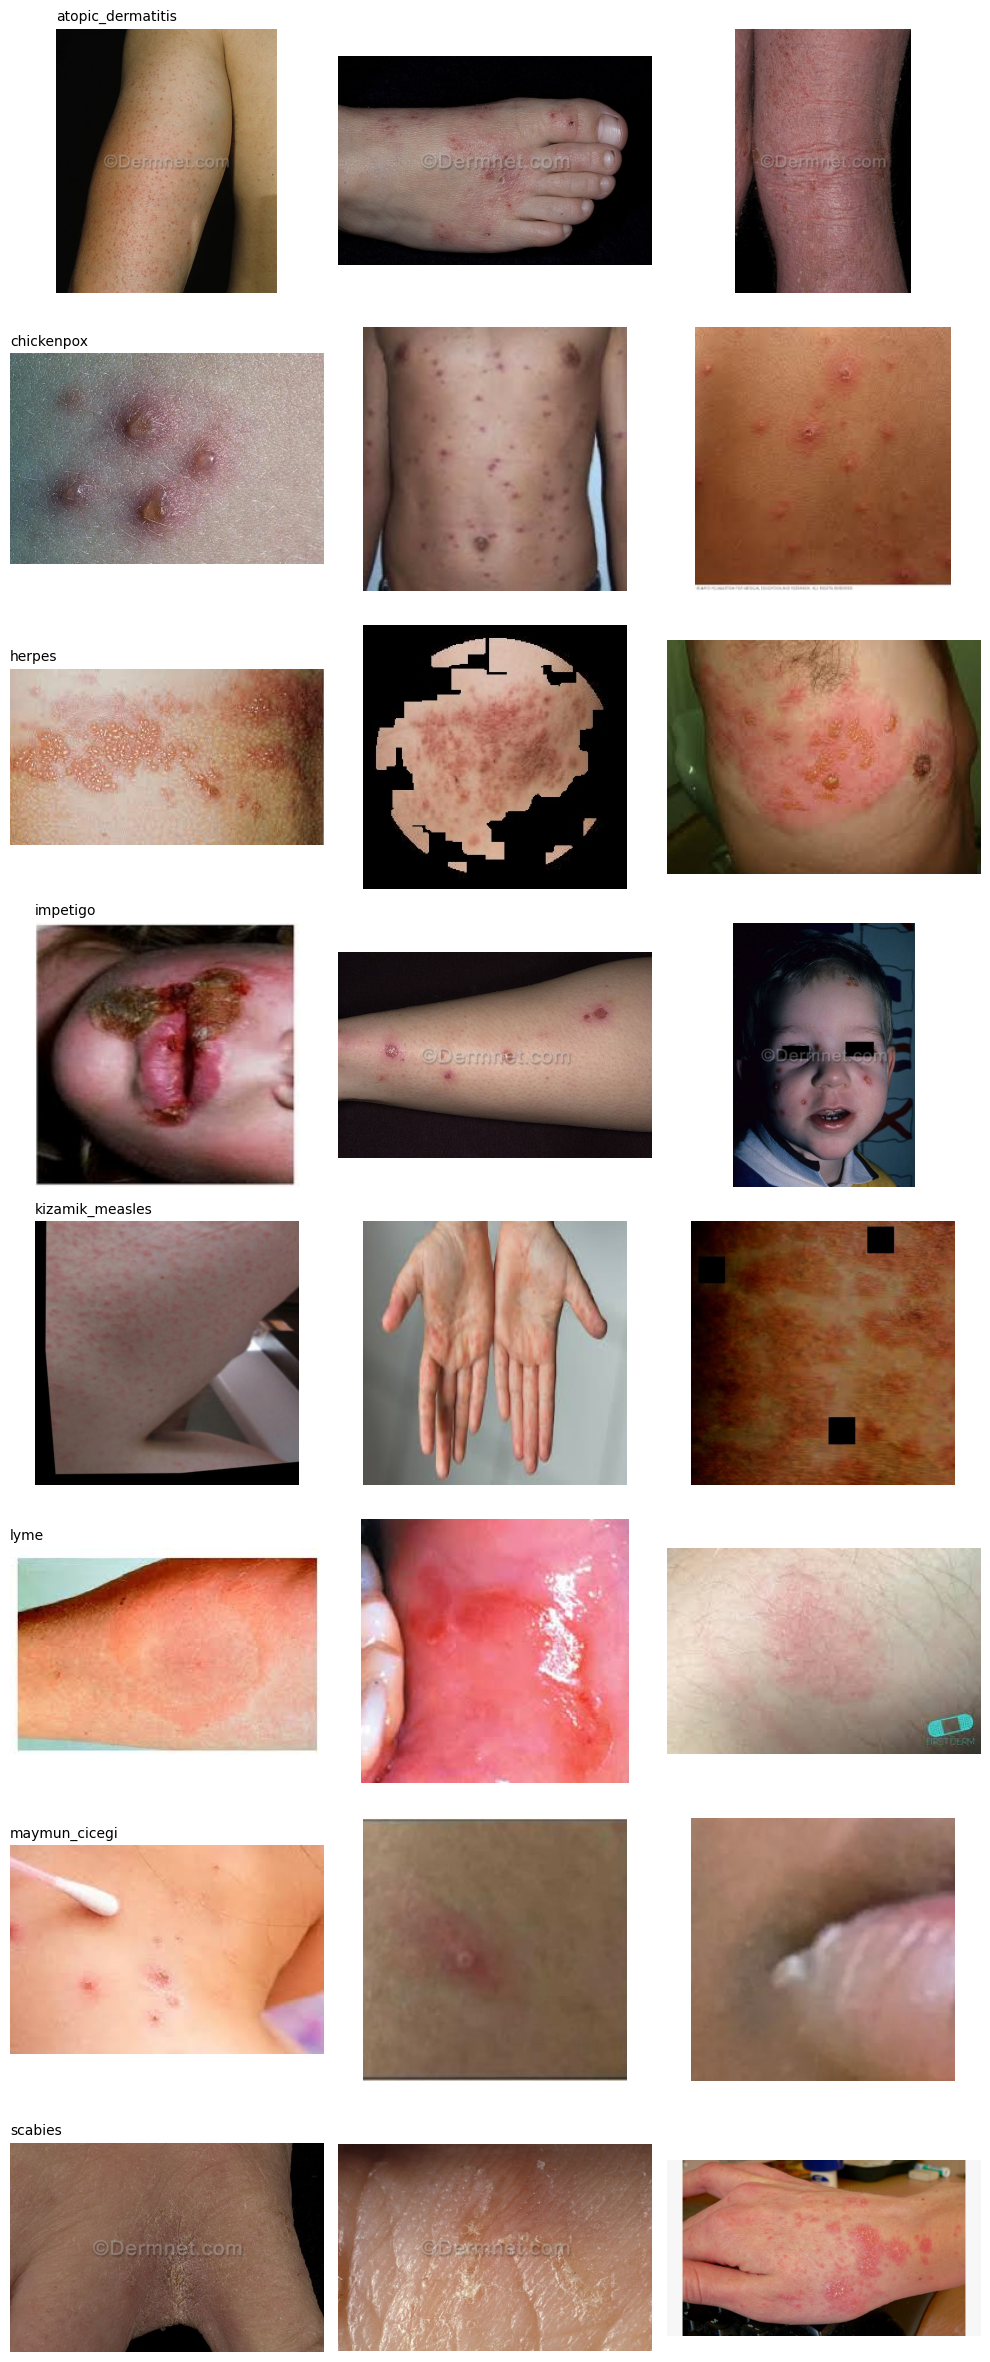

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(siniflar), 3, figsize=(10, len(siniflar)*3))

for i, sinif in enumerate(siniflar):
    sinif_yolu = os.path.join(veri_yolu, sinif)
    dosyalar = os.listdir(sinif_yolu)
    ornekler = random.sample(dosyalar, min(3, len(dosyalar)))
    for j, dosya in enumerate(ornekler):
        img = Image.open(os.path.join(sinif_yolu, dosya))
        axes[i, j].imshow(img)
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_ylabel(sinif, fontsize=12)
    axes[i, 0].set_title(sinif, fontsize=10, loc='left')

plt.tight_layout()
plt.show()

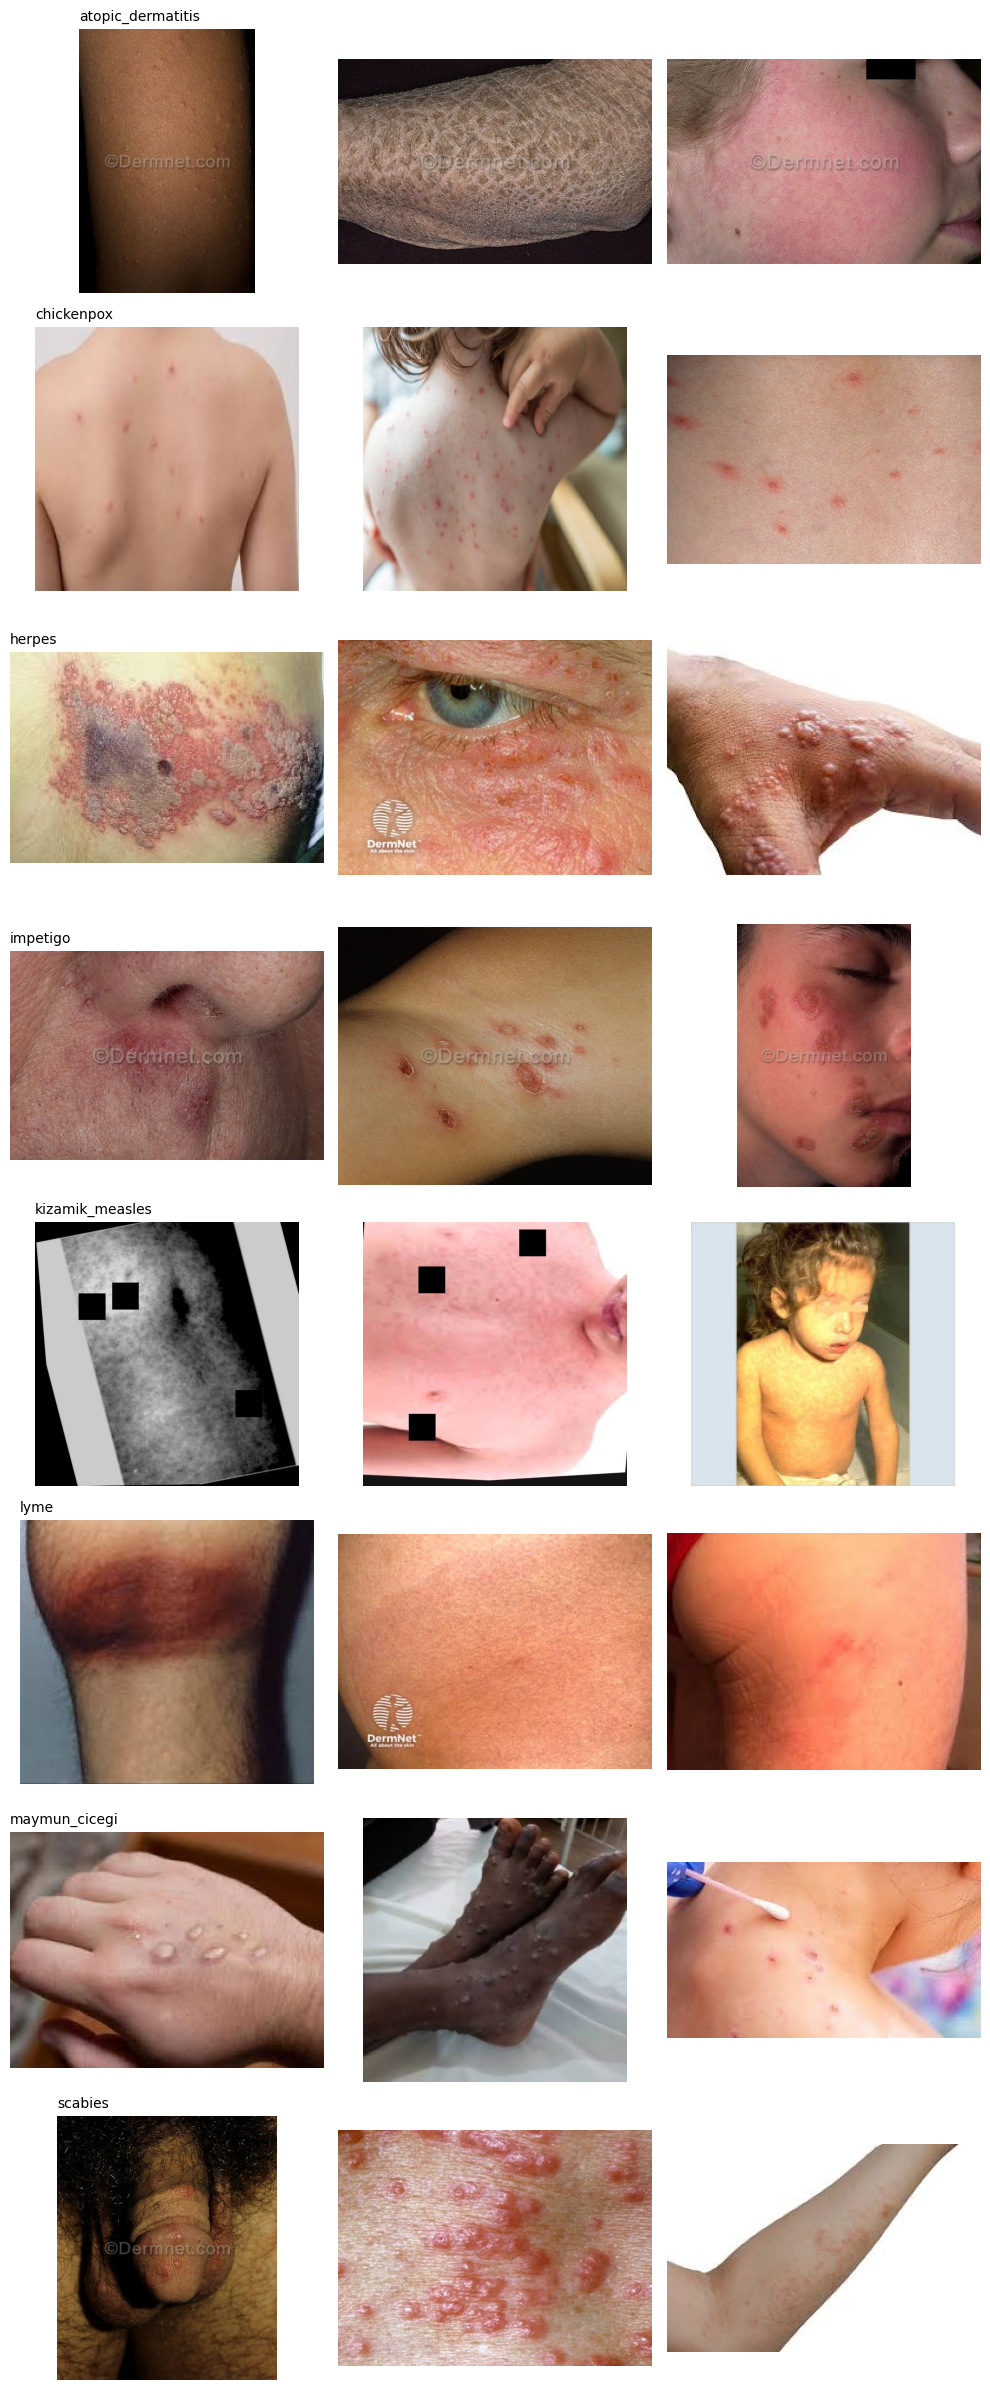

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(siniflar), 3, figsize=(10, len(siniflar)*3))

for i, sinif in enumerate(siniflar):
    sinif_yolu = os.path.join(veri_yolu, sinif)
    dosyalar = os.listdir(sinif_yolu)
    ornekler = random.sample(dosyalar, min(3, len(dosyalar)))
    for j, dosya in enumerate(ornekler):
        img = Image.open(os.path.join(sinif_yolu, dosya))
        axes[i, j].imshow(img)
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_ylabel(sinif, fontsize=12)
    axes[i, 0].set_title(sinif, fontsize=10, loc='left')

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

veriler = []
for sinif in siniflar:
    sinif_yolu = os.path.join(veri_yolu, sinif)
    for dosya in os.listdir(sinif_yolu):
        veriler.append({
            'dosya_yolu': os.path.join(sinif_yolu, dosya),
            'etiket': sinif
        })

df = pd.DataFrame(veriler)
print(df.shape)
print(df['etiket'].value_counts())

(4766, 2)
etiket
lyme                 953
kizamik_measles      948
maymun_cicegi        670
atopic_dermatitis    612
herpes               559
chickenpox           513
scabies              358
impetigo             153
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

# 1. aşama: %80 train_val, %20 test
train_val_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df['etiket'],
    random_state=42
)

# 2. aşama: train_val'in %10'u validation
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.10,
    stratify=train_val_df['etiket'],
    random_state=42
)

print(f"Train: {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"Test: {len(test_df)}")

Train: 3430
Validation: 382
Test: 954


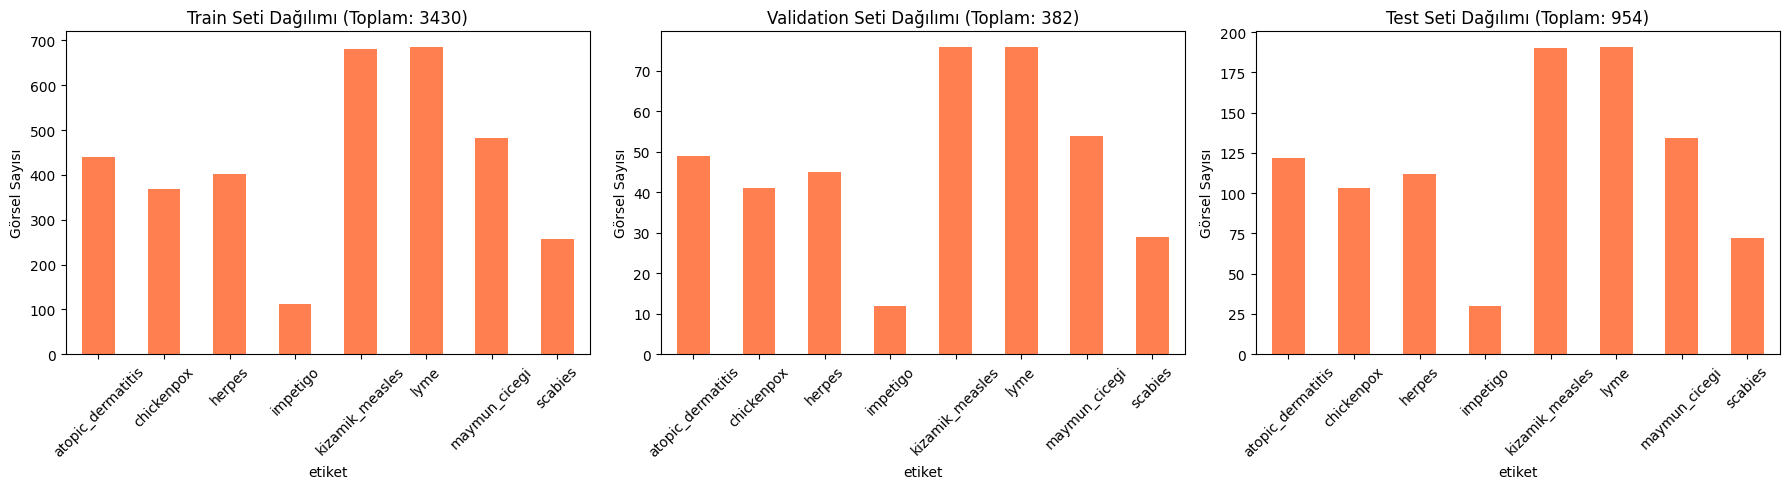

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18,5))

for ax, (isim, veri) in zip(axes, [('Train', train_df), ('Validation', val_df), ('Test', test_df)]):
    veri['etiket'].value_counts().sort_index().plot(kind='bar', ax=ax, color='coral')
    ax.set_title(f"{isim} Seti Dağılımı (Toplam: {len(veri)})")
    ax.set_ylabel("Görsel Sayısı")
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
proje_yolu = '/content/drive/MyDrive/Deri_Lezyonu_Projesi'

train_df.to_csv(os.path.join(proje_yolu, 'train_split.csv'), index=False)
val_df.to_csv(os.path.join(proje_yolu, 'val_split.csv'), index=False)
test_df.to_csv(os.path.join(proje_yolu, 'test_split.csv'), index=False)

print("Kaydedildi.")

Kaydedildi.


In [ ]:
import numpy as np

siniflar = sorted(df['etiket'].unique())
sinif_to_index = {sinif: i for i, sinif in enumerate(siniflar)}
print(sinif_to_index)

{'atopic_dermatitis': 0, 'chickenpox': 1, 'herpes': 2, 'impetigo': 3, 'kizamik_measles': 4, 'lyme': 5, 'maymun_cicegi': 6, 'scabies': 7}


In [ ]:
import tensorflow as tf

IMG_SIZE = 224

def goruntu_yukle(dosya_yolu, etiket):
    img = tf.io.read_file(dosya_yolu)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    # NOT: görsel 0-255 aralığında kalıyor
    return img, etiket

In [ ]:
augmentasyon = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.15),       # +-15% döndürme (~54 derece)
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomTranslation(0.1, 0.1), # hafif kaydırma
    tf.keras.layers.RandomContrast(0.15),
    tf.keras.layers.RandomBrightness(0.15),
])

In [ ]:
def dataset_olustur(dataframe, augment=False, batch_size=32, shuffle=False):
    yollar = dataframe['dosya_yolu'].values
    etiketler = dataframe['etiket'].map(sinif_to_index).values
    etiketler = tf.keras.utils.to_categorical(etiketler, num_classes=len(siniflar))

    ds = tf.data.Dataset.from_tensor_slices((yollar, etiketler))

    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe), seed=42)

    ds = ds.map(goruntu_yukle, num_parallel_calls=tf.data.AUTOTUNE)

    if augment:
        ds = ds.map(lambda x, y: (augmentasyon(x, training=True), y),
                     num_parallel_calls=tf.data.AUTOTUNE)

    # Normalizasyon: artık augmentasyondan SONRA, 0-255 -> 0-1
    ds = ds.map(lambda x, y: (x / 255.0, y), num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(batch_size)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = dataset_olustur(train_df, augment=True, shuffle=True)
val_ds   = dataset_olustur(val_df, augment=False, shuffle=False)
test_ds  = dataset_olustur(test_df, augment=False, shuffle=False)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

train_etiketler_sayisal = train_df['etiket'].map(sinif_to_index).values

class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(len(siniflar)),
    y=train_etiketler_sayisal
)

class_weights = dict(enumerate(class_weights_array))
for sinif, idx in sinif_to_index.items():
    print(f"{sinif}: {class_weights[idx]:.3f}")

atopic_dermatitis: 0.972
chickenpox: 1.162
herpes: 1.067
impetigo: 3.863
kizamik_measles: 0.629
lyme: 0.625
maymun_cicegi: 0.890
scabies: 1.668


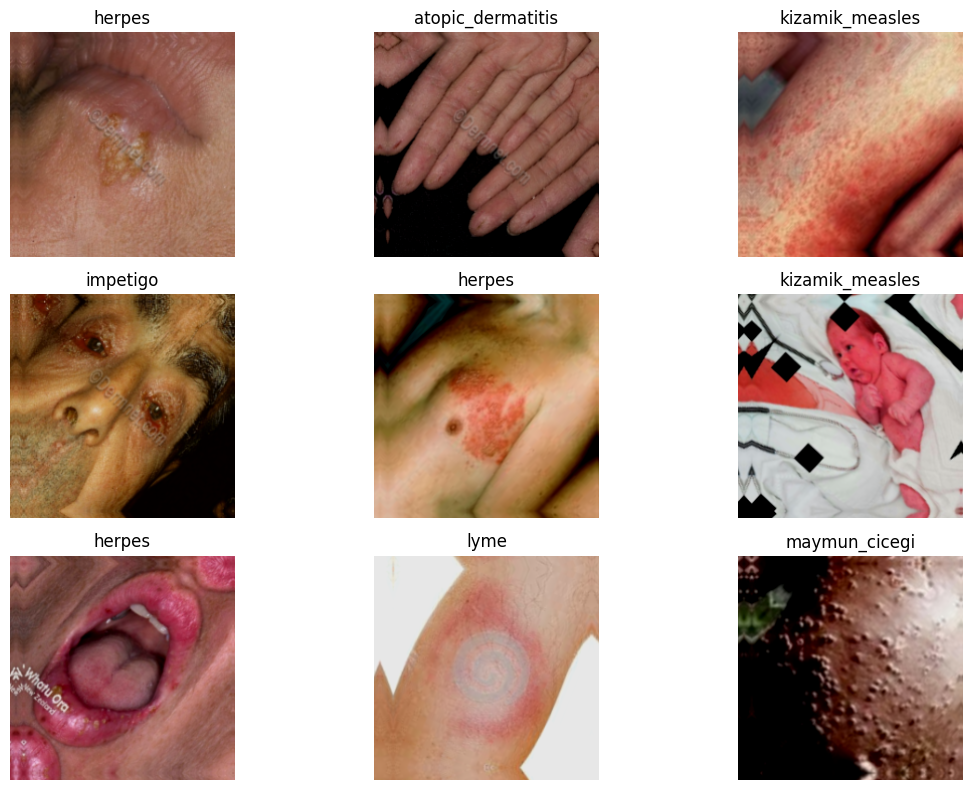

In [ ]:
import matplotlib.pyplot as plt

for goruntuler, etiketler in train_ds.take(1):
    plt.figure(figsize=(12, 8))
    for i in range(9):
        plt.subplot(3, 3, i+1)
        plt.imshow(goruntuler[i].numpy())
        sinif_index = np.argmax(etiketler[i].numpy())
        plt.title(siniflar[sinif_index])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers

def depthwise_separable_blok(x, filtre_sayisi, strides=1, l2_oran=1e-4):
    """
    Bir depthwise separable convolution bloğu:
    - Depthwise conv: her kanala ayrı ayrı 3x3 filtre uygular (mekansal özellik)
    - Pointwise conv: 1x1 konvolüsyon ile kanalları birleştirir (kanal karışımı)
    Bu ikili yapı, normal Conv2D'ye göre çok daha az parametre kullanır.
    """
    x = layers.DepthwiseConv2D(3, strides=strides, padding='same',
                                 depthwise_regularizer=regularizers.l2(l2_oran),
                                 use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(filtre_sayisi, 1, padding='same',
                       kernel_regularizer=regularizers.l2(l2_oran),
                       use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    return x

In [ ]:
def skip_connection_ekle(x, kisayol, filtre_sayisi):
    """
    Eğer giriş ile çıkışın boyutları (kanal sayısı, mekansal boyut) uyuşmuyorsa,
    1x1 konvolüsyon ile kısayolu (shortcut) hedef boyuta getirip toplama yaparız.
    Bu, derin katmanlarda bilginin kaybolmasını (vanishing gradient) azaltır.
    """
    if kisayol.shape[-1] != filtre_sayisi or kisayol.shape[1] != x.shape[1]:
        kisayol = layers.Conv2D(filtre_sayisi, 1, strides=(kisayol.shape[1] // x.shape[1]),
                                  padding='same', use_bias=False)(kisayol)
        kisayol = layers.BatchNormalization()(kisayol)

    return layers.Add()([x, kisayol])

In [ ]:
def dermanet_lite_olustur(giris_boyutu=(224, 224, 3), sinif_sayisi=8):
    girisler = layers.Input(shape=giris_boyutu)

    # --- STEM BLOK: Normal Conv2D ile hızlı boyut küçültme ---
    x = layers.Conv2D(32, 3, strides=2, padding='same', use_bias=False)(girisler)  # 224 -> 112
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # --- BLOK 1: 112x112 -> 112x112 (boyut sabit) ---
    x = depthwise_separable_blok(x, 64)

    # --- BLOK 2: 112x112 -> 56x56, skip connection ile ---
    kisayol = x
    x = depthwise_separable_blok(x, 128, strides=2)
    x = depthwise_separable_blok(x, 128)
    x = skip_connection_ekle(x, kisayol, 128)

    # --- BLOK 3: 56x56 -> 28x28 ---
    x = depthwise_separable_blok(x, 256, strides=2)
    x = depthwise_separable_blok(x, 256)

    # --- BLOK 4: 28x28 -> 14x14, skip connection ile ---
    kisayol = x
    x = depthwise_separable_blok(x, 512, strides=2)
    x = depthwise_separable_blok(x, 512)
    x = skip_connection_ekle(x, kisayol, 512)

    # --- BLOK 5: 14x14 -> 7x7 ---
    x = depthwise_separable_blok(x, 512, strides=2)
    x = depthwise_separable_blok(x, 512)

    # --- SINIFLANDIRMA BAŞLIĞI ---
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, kernel_regularizer=regularizers.l2(1e-4), use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dropout(0.3)(x)

    cikislar = layers.Dense(sinif_sayisi, activation='softmax')(x)

    model = models.Model(inputs=girisler, outputs=cikislar, name='DermaNet_Lite')
    return model

model = dermanet_lite_olustur()
model.summary()

Model: "DermaNet_Lite"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_12[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_20 (ReLU)     │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_9  │ (None, 112, 112,  │        288 │ re_lu_20[0][0]    │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ depthwise_conv2d… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_21 (ReLU)     │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 112, 112,  │      2,048 │ re_lu_21[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        256 │ conv2d_13[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_22 (ReLU)     │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_10 │ (None, 56, 56,    │        576 │ re_lu_22[0][0]    │
│ (DepthwiseConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ depthwise_conv2d… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_23 (ReLU)     │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 56, 56,    │      8,192 │ re_lu_23[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        512 │ conv2d_14[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_24 (ReLU)     │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ depthwise_conv2d_11 │ (None, 56, 56,    │      1,152 │ re_lu_24[0][0]  

 Total params: 1,362,120 (5.20 MB)

 Trainable params: 1,349,704 (5.15 MB)

 Non-trainable params: 12,416 (48.50 KB)

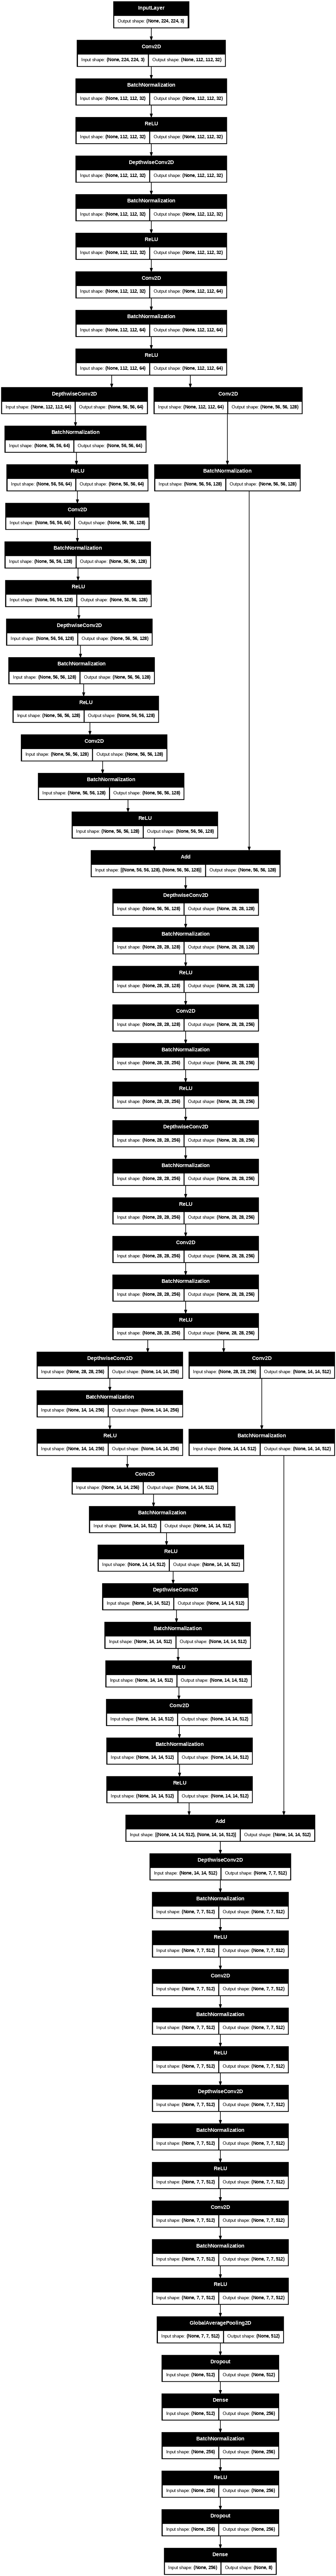

In [ ]:
tf.keras.utils.plot_model(model, to_file='dermanet_lite_mimari.png',
                            show_shapes=True, show_layer_names=False, dpi=70)

In [ ]:
print("GPU kullanılabilir mi:", tf.config.list_physical_devices('GPU'))

GPU kullanılabilir mi: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name='auc', multi_label=True)
    ]
)

In [ ]:
from sklearn.metrics import f1_score
import numpy as np

class F1ScoreCallback(tf.keras.callbacks.Callback):
    def __init__(self, val_ds):
        super().__init__()
        self.val_ds = val_ds
        self.val_f1_listesi = []
        self.train_f1_listesi = []

    def _f1_hesapla(self, dataset):
        y_true, y_pred = [], []
        for x_batch, y_batch in dataset:
            tahminler = self.model.predict(x_batch, verbose=0)
            y_pred.extend(np.argmax(tahminler, axis=1))
            y_true.extend(np.argmax(y_batch.numpy(), axis=1))
        return f1_score(y_true, y_pred, average='macro')

    def on_epoch_end(self, epoch, logs=None):
        val_f1 = self._f1_hesapla(self.val_ds)
        self.val_f1_listesi.append(val_f1)
        print(f" - val_f1 (macro): {val_f1:.4f}")

In [ ]:
callbacks_listesi = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath='/content/drive/MyDrive/Deri_Lezyonu_Projesi/en_iyi_model.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    )
]

f1_callback = F1ScoreCallback(val_ds)

In [ ]:
EPOCHS = 50  # EarlyStopping zaten gerektiğinde erken durduracak

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks_listesi + [f1_callback],
    verbose=1
)

Epoch 1/50
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 514ms/step - accuracy: 0.1875 - auc: 0.5777 - loss: 2.6029
Epoch 1: val_accuracy improved from None to 0.12827, saving model to /content/drive/MyDrive/Deri_Lezyonu_Projesi/en_iyi_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Deri_Lezyonu_Projesi/en_iyi_model.keras
 - val_f1 (macro): 0.0284
108/108 ━━━━━━━━━━━━━━━━━━━━ 119s 726ms/step - accuracy: 0.2111 - auc: 0.6030 - loss: 2.4957 - val_accuracy: 0.1283 - val_auc: 0.5000 - val_loss: 2.4418 - learning_rate: 0.0010
Epoch 2/50
107/108 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.2804 - auc: 0.6743 - loss: 2.2658
Epoch 2: val_accuracy did not improve from 0.12827
 - val_f1 (macro): 0.0284
108/108 ━━━━━━━━━━━━━━━━━━━━ 15s 135ms/step - accuracy: 0.2708 - auc: 0.6741 - loss: 2.2655 - val_accuracy: 0.1283 - val_auc: 0.5000 - val_loss: 2.6327 - learning_rate: 0.0010
Epoch 3/50
107/108 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.3138 - auc: 0.7080 - loss: 2.2174
Epoch 3:

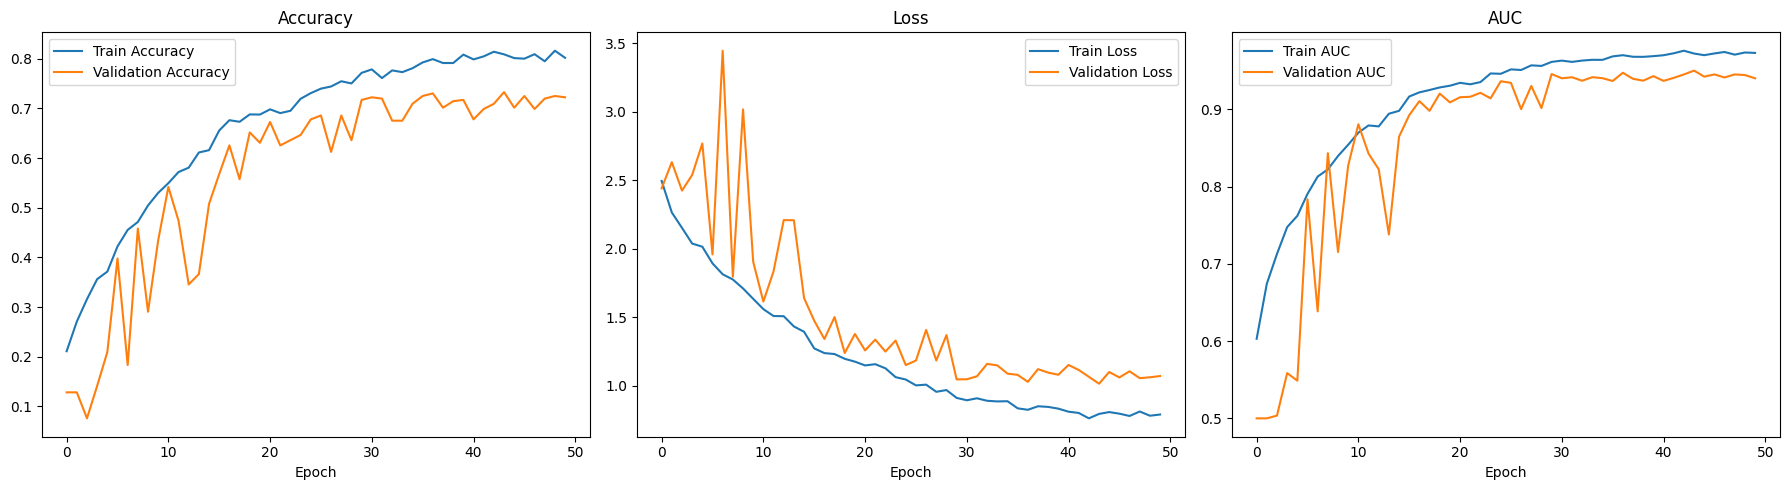

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Accuracy
axes[0].plot(history.history['accuracy'], label='Train Accuracy')
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()

# Loss
axes[1].plot(history.history['loss'], label='Train Loss')
axes[1].plot(history.history['val_loss'], label='Validation Loss')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()

# AUC
axes[2].plot(history.history['auc'], label='Train AUC')
axes[2].plot(history.history['val_auc'], label='Validation AUC')
axes[2].set_title('AUC')
axes[2].set_xlabel('Epoch')
axes[2].legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Deri_Lezyonu_Projesi/egitim_grafikleri.png', dpi=150)
plt.show()

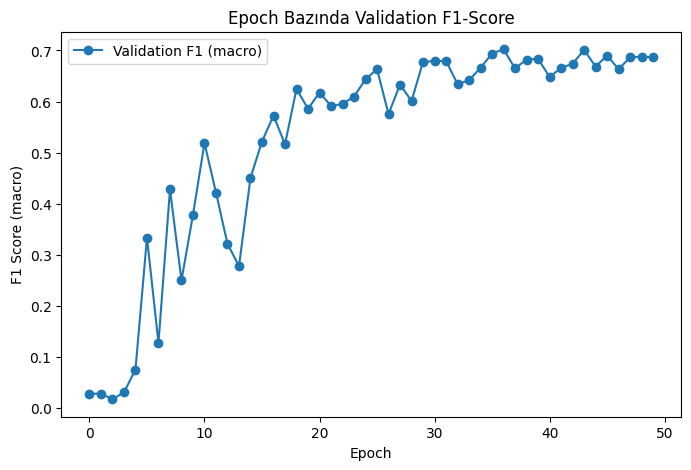

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(f1_callback.val_f1_listesi, label='Validation F1 (macro)', marker='o')
plt.title('Epoch Bazında Validation F1-Score')
plt.xlabel('Epoch')
plt.ylabel('F1 Score (macro)')
plt.legend()
plt.savefig('/content/drive/MyDrive/Deri_Lezyonu_Projesi/f1_grafigi.png', dpi=150)
plt.show()

In [ ]:
en_iyi_model = tf.keras.models.load_model('/content/drive/MyDrive/Deri_Lezyonu_Projesi/en_iyi_model.keras')

In [ ]:
import numpy as np

y_true = []
y_pred = []
y_probs = []

for x_batch, y_batch in test_ds:
    probs = en_iyi_model.predict(x_batch, verbose=0)
    y_probs.extend(probs)
    y_pred.extend(np.argmax(probs, axis=1))
    y_true.extend(np.argmax(y_batch.numpy(), axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_probs = np.array(y_probs)

print("Toplam test örneği:", len(y_true))

Toplam test örneği: 954


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

test_accuracy = accuracy_score(y_true, y_pred)
test_f1_macro = f1_score(y_true, y_pred, average='macro')
test_auc_macro = roc_auc_score(y_true, y_probs, multi_class='ovr', average='macro')

print(f"Test Accuracy     : {test_accuracy:.4f}")
print(f"Test F1 (macro)   : {test_f1_macro:.4f}")
print(f"Test AUC (macro)  : {test_auc_macro:.4f}")

Test Accuracy     : 0.7484
Test F1 (macro)   : 0.7003
Test AUC (macro)  : 0.9424


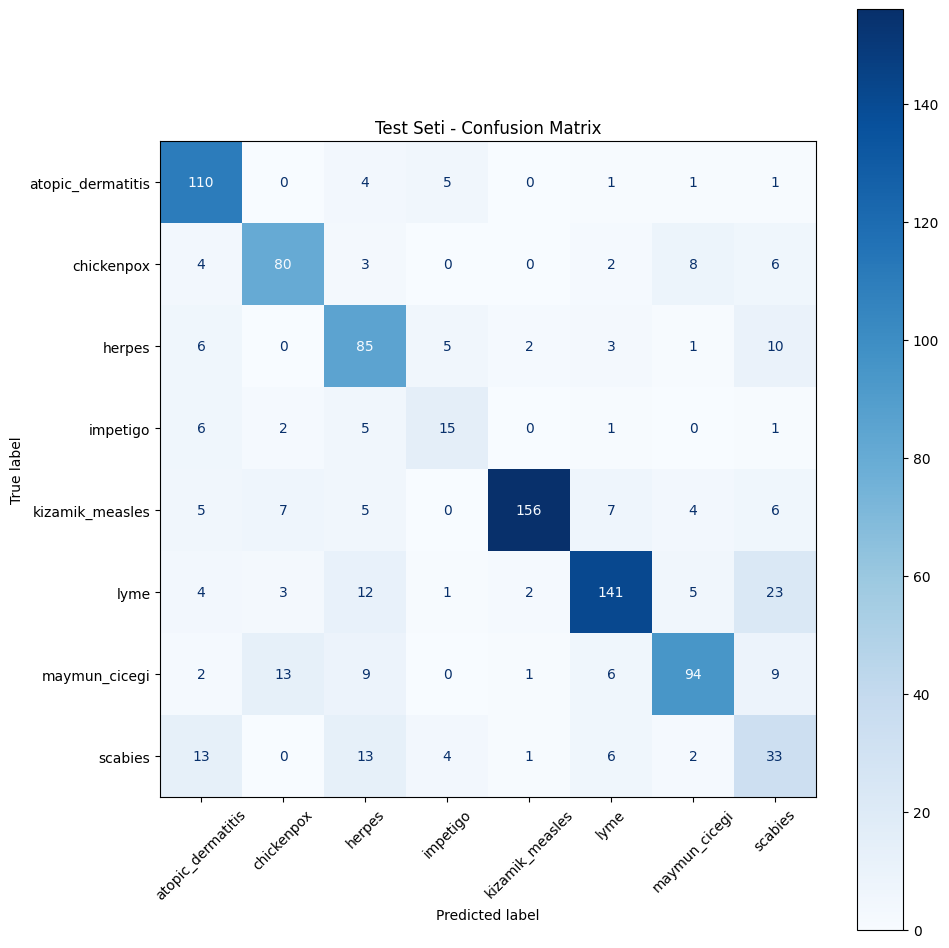

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=siniflar)
disp.plot(ax=ax, xticks_rotation=45, cmap='Blues', colorbar=True)
plt.title("Test Seti - Confusion Matrix")
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Deri_Lezyonu_Projesi/confusion_matrix.png', dpi=150)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

rapor = classification_report(y_true, y_pred, target_names=siniflar, digits=3)
print(rapor)

                   precision    recall  f1-score   support

atopic_dermatitis      0.733     0.902     0.809       122
       chickenpox      0.762     0.777     0.769       103
           herpes      0.625     0.759     0.685       112
         impetigo      0.500     0.500     0.500        30
  kizamik_measles      0.963     0.821     0.886       190
             lyme      0.844     0.738     0.788       191
    maymun_cicegi      0.817     0.701     0.755       134
          scabies      0.371     0.458     0.410        72

         accuracy                          0.748       954
        macro avg      0.702     0.707     0.700       954
     weighted avg      0.769     0.748     0.754       954



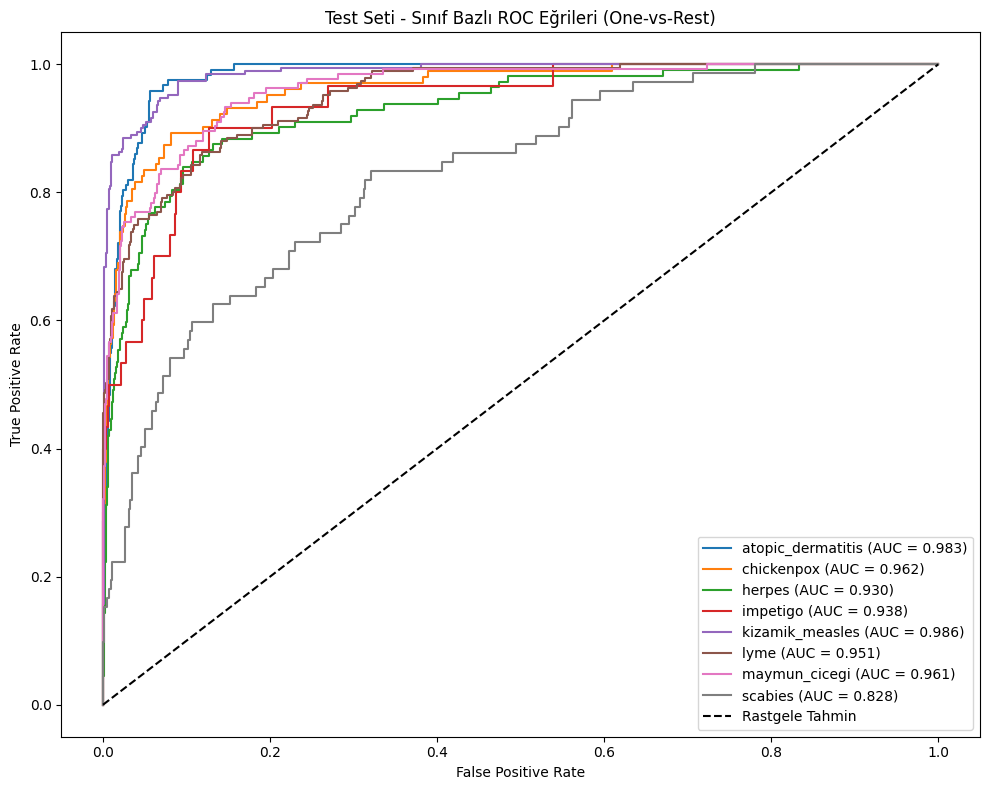


Sınıf bazlı AUC değerleri:
  atopic_dermatitis: 0.9828
  chickenpox: 0.9619
  herpes: 0.9303
  impetigo: 0.9376
  kizamik_measles: 0.9865
  lyme: 0.9512
  maymun_cicegi: 0.9608
  scabies: 0.8280


In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

y_true_bin = label_binarize(y_true, classes=range(len(siniflar)))

plt.figure(figsize=(10, 8))
auc_skorlari = {}

for i, sinif in enumerate(siniflar):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
    roc_auc = auc(fpr, tpr)
    auc_skorlari[sinif] = roc_auc
    plt.plot(fpr, tpr, label=f'{sinif} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Rastgele Tahmin')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Test Seti - Sınıf Bazlı ROC Eğrileri (One-vs-Rest)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Deri_Lezyonu_Projesi/roc_egrileri.png', dpi=150)
plt.show()

print("\nSınıf bazlı AUC değerleri:")
for sinif, deger in auc_skorlari.items():
    print(f"  {sinif}: {deger:.4f}")

In [ ]:
import tensorflow as tf
from tensorflow.keras import backend as K
import numpy as np
#6.5.1
# Daha önce hesapladığımız class_weights_array'i alpha olarak kullanıyoruz
alpha_vektoru = tf.constant(class_weights_array, dtype=tf.float32)
gamma_degeri = 2.0

def categorical_focal_loss(y_true, y_pred):
    y_pred = tf.clip_by_value(y_pred, K.epsilon(), 1.0 - K.epsilon())
    cross_entropy = -y_true * tf.math.log(y_pred)
    agirlik = alpha_vektoru * tf.math.pow(1 - y_pred, gamma_degeri)
    loss = agirlik * cross_entropy
    return tf.reduce_sum(loss, axis=-1)

In [ ]:
#6.5.2
en_iyi_model = tf.keras.models.load_model('/content/drive/MyDrive/Deri_Lezyonu_Projesi/en_iyi_model.keras')

en_iyi_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),  # düşük lr - ince ayar için
    loss=categorical_focal_loss,
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc', multi_label=True)]
)

In [ ]:
#6.5.3
callbacks_v2 = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath='/content/drive/MyDrive/Deri_Lezyonu_Projesi/en_iyi_model_v2.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=6,
        restore_best_weights=True,
        verbose=1
    )
]

f1_callback_v2 = F1ScoreCallback(val_ds)

In [ ]:
EPOCHS_V2 = 20
#6.5.4
history_v2 = en_iyi_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_V2,
    callbacks=callbacks_v2 + [f1_callback_v2],
    verbose=1
)

Epoch 1/20
108/108 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - accuracy: 0.8008 - auc: 0.9695 - loss: 0.5629
Epoch 1: val_accuracy improved from None to 0.67016, saving model to /content/drive/MyDrive/Deri_Lezyonu_Projesi/en_iyi_model_v2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Deri_Lezyonu_Projesi/en_iyi_model_v2.keras
 - val_f1 (macro): 0.6249
108/108 ━━━━━━━━━━━━━━━━━━━━ 68s 402ms/step - accuracy: 0.7942 - auc: 0.9692 - loss: 0.5726 - val_accuracy: 0.6702 - val_auc: 0.9222 - val_loss: 1.0599
Epoch 2/20
107/108 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.7812 - auc: 0.9692 - loss: 0.5683
Epoch 2: val_accuracy improved from 0.67016 to 0.69372, saving model to /content/drive/MyDrive/Deri_Lezyonu_Projesi/en_iyi_model_v2.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Deri_Lezyonu_Projesi/en_iyi_model_v2.keras
 - val_f1 (macro): 0.6487
108/108 ━━━━━━━━━━━━━━━━━━━━ 15s 141ms/step - accuracy: 0.7948 - auc: 0.9720 - loss: 0.5431 - val_accuracy: 0.6937 - 

In [ ]:
#6.5.5
y_true_v2, y_pred_v2, y_probs_v2 = [], [], []

for x_batch, y_batch in test_ds:
    probs = en_iyi_model.predict(x_batch, verbose=0)
    y_probs_v2.extend(probs)
    y_pred_v2.extend(np.argmax(probs, axis=1))
    y_true_v2.extend(np.argmax(y_batch.numpy(), axis=1))

y_true_v2 = np.array(y_true_v2)
y_pred_v2 = np.array(y_pred_v2)
y_probs_v2 = np.array(y_probs_v2)

print("Test Accuracy (v2):", accuracy_score(y_true_v2, y_pred_v2))
print("Test F1 macro (v2):", f1_score(y_true_v2, y_pred_v2, average='macro'))
print("Test AUC macro (v2):", roc_auc_score(y_true_v2, y_probs_v2, multi_class='ovr', average='macro'))

print(classification_report(y_true_v2, y_pred_v2, target_names=siniflar, digits=3))

Test Accuracy (v2): 0.69916142557652
Test F1 macro (v2): 0.6504671955808712
Test AUC macro (v2): 0.9322290730772302
                   precision    recall  f1-score   support

atopic_dermatitis      0.664     0.730     0.695       122
       chickenpox      0.741     0.777     0.758       103
           herpes      0.569     0.696     0.627       112
         impetigo      0.308     0.667     0.421        30
  kizamik_measles      0.912     0.821     0.864       190
             lyme      0.890     0.681     0.772       191
    maymun_cicegi      0.789     0.642     0.708       134
          scabies      0.333     0.389     0.359        72

         accuracy                          0.699       954
        macro avg      0.651     0.675     0.650       954
     weighted avg      0.737     0.699     0.711       954



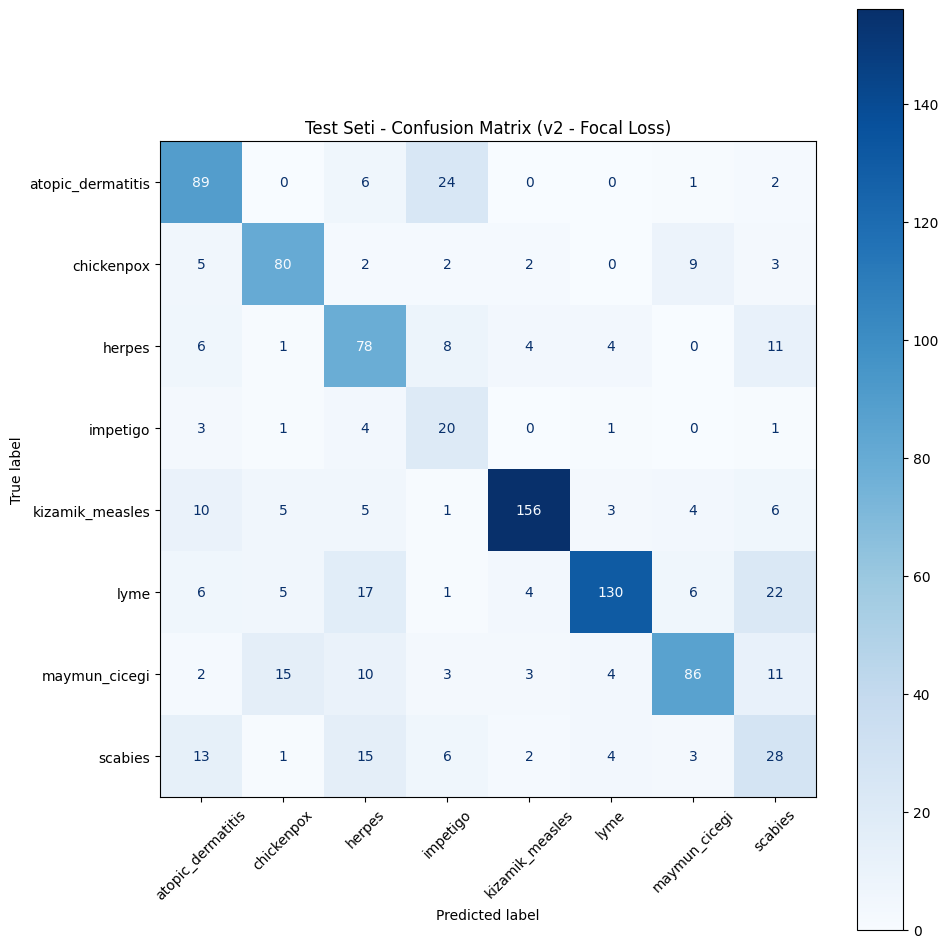

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_v2 = confusion_matrix(y_true_v2, y_pred_v2)

fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_v2, display_labels=siniflar)
disp.plot(ax=ax, xticks_rotation=45, cmap='Blues', colorbar=True)
plt.title("Test Seti - Confusion Matrix (v2 - Focal Loss)")
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Deri_Lezyonu_Projesi/confusion_matrix_v2.png', dpi=150)
plt.show()

In [ ]:
train_val_birlesik = pd.concat([train_df, val_df], axis=0).reset_index(drop=True)
print("Birleşik train+val veri sayısı:", len(train_val_birlesik))
print(train_val_birlesik['etiket'].value_counts())

Birleşik train+val veri sayısı: 3812
etiket
lyme                 762
kizamik_measles      758
maymun_cicegi        536
atopic_dermatitis    490
herpes               447
chickenpox           410
scabies              286
impetigo             123
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight
import pandas as pd

K_FOLD = 5
skf = StratifiedKFold(n_splits=K_FOLD, shuffle=True, random_state=42)

etiketler_sayisal_birlesik = train_val_birlesik['etiket'].map(sinif_to_index).values

fold_sonuclari = []

for fold_no, (train_idx, val_idx) in enumerate(skf.split(train_val_birlesik, etiketler_sayisal_birlesik), start=1):
    print(f"\n========== FOLD {fold_no}/{K_FOLD} ==========")

    fold_train_df = train_val_birlesik.iloc[train_idx].reset_index(drop=True)
    fold_val_df = train_val_birlesik.iloc[val_idx].reset_index(drop=True)

    fold_train_ds = dataset_olustur(fold_train_df, augment=True, shuffle=True)
    fold_val_ds = dataset_olustur(fold_val_df, augment=False, shuffle=False)

    # Her fold için sıfırdan yeni model
    fold_model = dermanet_lite_olustur()
    fold_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc', multi_label=True)]
    )

    # Bu fold'a özel class weight
    fold_class_weights_array = compute_class_weight(
        class_weight='balanced',
        classes=np.arange(len(siniflar)),
        y=fold_train_df['etiket'].map(sinif_to_index).values
    )
    fold_class_weights = dict(enumerate(fold_class_weights_array))

    fold_callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=0),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=0)
    ]

    fold_model.fit(
        fold_train_ds,
        validation_data=fold_val_ds,
        epochs=30,
        class_weight=fold_class_weights,
        callbacks=fold_callbacks,
        verbose=2  # her epoch tek satır - çıktıyı kısa tutar
    )

    # Bu fold'un validation seti üzerinde değerlendirme
    y_true_f, y_pred_f, y_probs_f = [], [], []
    for x_batch, y_batch in fold_val_ds:
        probs = fold_model.predict(x_batch, verbose=0)
        y_probs_f.extend(probs)
        y_pred_f.extend(np.argmax(probs, axis=1))
        y_true_f.extend(np.argmax(y_batch.numpy(), axis=1))

    y_true_f = np.array(y_true_f)
    y_pred_f = np.array(y_pred_f)
    y_probs_f = np.array(y_probs_f)

    acc = accuracy_score(y_true_f, y_pred_f)
    f1 = f1_score(y_true_f, y_pred_f, average='macro')
    auc_v = roc_auc_score(y_true_f, y_probs_f, multi_class='ovr', average='macro')

    print(f"\nFOLD {fold_no} SONUCU -> Accuracy: {acc:.4f} | F1 macro: {f1:.4f} | AUC macro: {auc_v:.4f}")

    fold_sonuclari.append({'fold': fold_no, 'accuracy': acc, 'f1_macro': f1, 'auc_macro': auc_v})


========== FOLD 1/5 ==========
Epoch 1/30
96/96 - 74s - 773ms/step - accuracy: 0.1929 - auc: 0.5975 - loss: 2.5054 - val_accuracy: 0.0747 - val_auc: 0.5000 - val_loss: 2.4937 - learning_rate: 0.0010
Epoch 2/30
96/96 - 13s - 131ms/step - accuracy: 0.2532 - auc: 0.6559 - loss: 2.3275 - val_accuracy: 0.1402 - val_auc: 0.5000 - val_loss: 2.6693 - learning_rate: 0.0010
Epoch 3/30
96/96 - 13s - 132ms/step - accuracy: 0.2801 - auc: 0.6926 - loss: 2.2212 - val_accuracy: 0.1402 - val_auc: 0.5127 - val_loss: 2.5325 - learning_rate: 0.0010
Epoch 4/30
96/96 - 13s - 130ms/step - accuracy: 0.3037 - auc: 0.7056 - loss: 2.1807 - val_accuracy: 0.1402 - val_auc: 0.5915 - val_loss: 2.5055 - learning_rate: 0.0010
Epoch 5/30
96/96 - 13s - 131ms/step - accuracy: 0.3641 - auc: 0.7588 - loss: 2.0211 - val_accuracy: 0.1586 - val_auc: 0.6120 - val_loss: 2.6586 - learning_rate: 5.0000e-04
Epoch 6/30
96/96 - 13s - 131ms/step - accuracy: 0.4054 - auc: 0.7778 - loss: 1.9533 - val_accuracy: 0.2425 - val_auc: 0.6694

In [ ]:
sonuc_df = pd.DataFrame(fold_sonuclari)
print(sonuc_df)

print("\n--- K-FOLD CROSS-VALIDATION SONUÇLARI ---")
print(f"Ortalama Accuracy : {sonuc_df['accuracy'].mean():.4f} ± {sonuc_df['accuracy'].std():.4f}")
print(f"Ortalama F1 macro : {sonuc_df['f1_macro'].mean():.4f} ± {sonuc_df['f1_macro'].std():.4f}")
print(f"Ortalama AUC macro: {sonuc_df['auc_macro'].mean():.4f} ± {sonuc_df['auc_macro'].std():.4f}")

   fold  accuracy  f1_macro  auc_macro
0     1  0.560944  0.515601   0.848304
1     2  0.570118  0.526977   0.892792
2     3  0.650919  0.597902   0.909757
3     4  0.637795  0.569579   0.902948
4     5  0.673228  0.629337   0.913717

--- K-FOLD CROSS-VALIDATION SONUÇLARI ---
Ortalama Accuracy : 0.6186 ± 0.0502
Ortalama F1 macro : 0.5679 ± 0.0477
Ortalama AUC macro: 0.8935 ± 0.0265


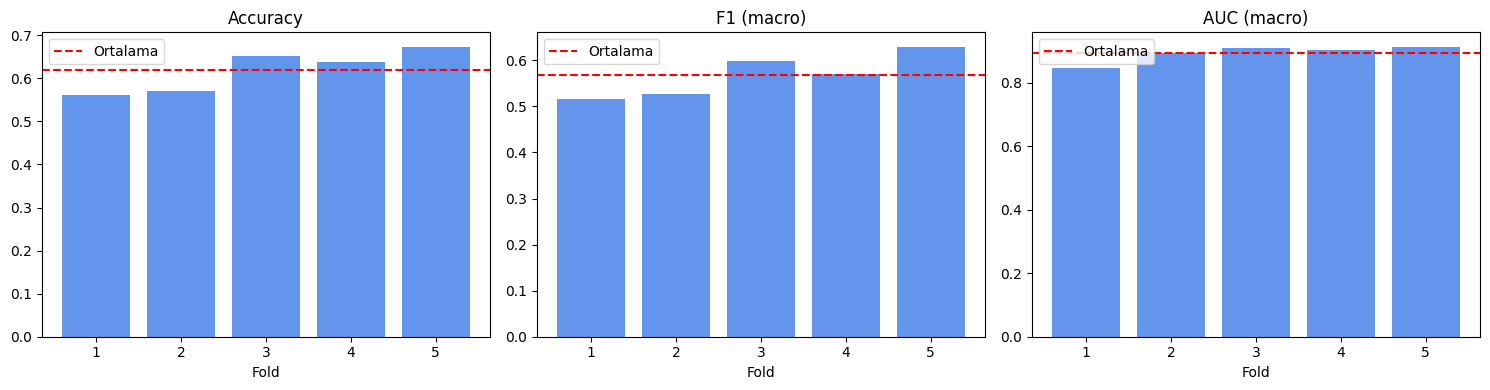

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metrik, baslik in zip(axes, ['accuracy', 'f1_macro', 'auc_macro'],
                                ['Accuracy', 'F1 (macro)', 'AUC (macro)']):
    ax.bar(sonuc_df['fold'], sonuc_df[metrik], color='cornflowerblue')
    ax.axhline(sonuc_df[metrik].mean(), color='red', linestyle='--', label='Ortalama')
    ax.set_title(baslik)
    ax.set_xlabel('Fold')
    ax.set_xticks(sonuc_df['fold'])
    ax.legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/Deri_Lezyonu_Projesi/kfold_sonuclari.png', dpi=150)
plt.show()

In [ ]:
import tensorflow as tf

en_iyi_model = tf.keras.models.load_model('/content/drive/MyDrive/Deri_Lezyonu_Projesi/en_iyi_model.keras')

converter = tf.lite.TFLiteConverter.from_keras_model(en_iyi_model)
tflite_model = converter.convert()

with open('/content/drive/MyDrive/Deri_Lezyonu_Projesi/derma_model.tflite', 'wb') as f:
    f.write(tflite_model)

import os
boyut_mb = os.path.getsize('/content/drive/MyDrive/Deri_Lezyonu_Projesi/derma_model.tflite') / (1024*1024)
print(f"TFLite model boyutu (float32): {boyut_mb:.2f} MB")

Saved artifact at '/tmp/tmpcykxdf6u'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_2')
Output Type:
  TensorSpec(shape=(None, 8), dtype=tf.float32, name=None)
Captures:
  140515774811792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774814864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774816976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774814288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774812752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774816592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774813520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774815248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774814672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774814096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1405157748154

In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(en_iyi_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model_quant = converter.convert()

with open('/content/drive/MyDrive/Deri_Lezyonu_Projesi/derma_model_quant.tflite', 'wb') as f:
    f.write(tflite_model_quant)

boyut_mb_quant = os.path.getsize('/content/drive/MyDrive/Deri_Lezyonu_Projesi/derma_model_quant.tflite') / (1024*1024)
print(f"TFLite model boyutu (quantized): {boyut_mb_quant:.2f} MB")

Saved artifact at '/tmp/tmpxk34mub2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_2')
Output Type:
  TensorSpec(shape=(None, 8), dtype=tf.float32, name=None)
Captures:
  140515774811792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774814864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774816976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774814288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774812752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774816592: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774813520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774815248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774814672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140515774814096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1405157748154

In [ ]:
import numpy as np

interpreter = tf.lite.Interpreter(model_path='/content/drive/MyDrive/Deri_Lezyonu_Projesi/derma_model_quant.tflite')
interpreter.allocate_tensors()

giris_detay = interpreter.get_input_details()
cikis_detay = interpreter.get_output_details()

print("Giriş şekli:", giris_detay[0]['shape'], "tipi:", giris_detay[0]['dtype'])
print("Çıkış şekli:", cikis_detay[0]['shape'], "tipi:", cikis_detay[0]['dtype'])

y_true_tflite, y_pred_tflite, y_probs_tflite = [], [], []

for x_batch, y_batch in test_ds:
    for i in range(x_batch.shape[0]):
        goruntu = np.expand_dims(x_batch[i].numpy(), axis=0).astype(np.float32)
        interpreter.set_tensor(giris_detay[0]['index'], goruntu)
        interpreter.invoke()
        cikis = interpreter.get_tensor(cikis_detay[0]['index'])[0]

        y_probs_tflite.append(cikis)
        y_pred_tflite.append(np.argmax(cikis))
        y_true_tflite.append(np.argmax(y_batch[i].numpy()))

y_true_tflite = np.array(y_true_tflite)
y_pred_tflite = np.array(y_pred_tflite)
y_probs_tflite = np.array(y_probs_tflite)

print("\nTFLite (quantized) Test Accuracy:", accuracy_score(y_true_tflite, y_pred_tflite))
print("TFLite (quantized) Test F1 macro:", f1_score(y_true_tflite, y_pred_tflite, average='macro'))

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Giriş şekli: [  1 224 224   3] tipi: <class 'numpy.float32'>
Çıkış şekli: [1 8] tipi: <class 'numpy.float32'>

TFLite (quantized) Test Accuracy: 0.7484276729559748
TFLite (quantized) Test F1 macro: 0.6997111205761943


In [ ]:
import json

etiket_listesi = siniflar  # zaten alfabetik sıralı: ['atopic_dermatitis', 'chickenpox', ...]

with open('/content/drive/MyDrive/Deri_Lezyonu_Projesi/labels.txt', 'w', encoding='utf-8') as f:
    for etiket in etiket_listesi:
        f.write(etiket + '\n')

print("Etiket sırası:", etiket_listesi)

Etiket sırası: ['atopic_dermatitis', 'chickenpox', 'herpes', 'impetigo', 'kizamik_measles', 'lyme', 'maymun_cicegi', 'scabies']


In [ ]:
import os
proje_yolu = '/content/drive/MyDrive/Deri_Lezyonu_Projesi'
for dosya in os.listdir(proje_yolu):
    if dosya.endswith(('.tflite', '.txt', '.keras')):
        boyut = os.path.getsize(os.path.join(proje_yolu, dosya)) / (1024*1024)
        print(f"{dosya}: {boyut:.2f} MB")

deri_hastaligi_modeli.tflite: 99.51 MB
model_flutter_icin.tflite: 24.90 MB
en_iyi_model.keras: 15.79 MB
en_iyi_model_v2.keras: 15.79 MB
derma_model.tflite: 5.14 MB
derma_model_quant.tflite: 1.39 MB
labels.txt: 0.00 MB
